# Cross-repository exact-content overlap (RQ2)

**Research question:** To what extent are identical AI agent skills reused across different repositories?

This analysis uses the July 2026 GitSkills sample to identify identical `SKILL.md` contents across GitHub repositories. The sample contains 13,000 distinct contents selected by Git blob hash, together with their recorded occurrences. We calculate the proportion of distinct contents found in multiple repositories and the proportion of artifact occurrences represented by those contents.

Here, *reuse* refers only to exact-content overlap. Matching hashes do not establish whether a skill was copied, independently adopted, or redistributed through a shared source. The results describe the sampled contents and their occurrences, not the wider population of GitHub repositories.

The analysis also produces the cross-repository distribution shown in Figure 2 of the paper.

## 1. Database connection

The source is `data/raw/agent_skills_sample.db`. The database is opened in read-only mode, and the notebook can be launched from either the project root or the `notebooks` directory. Figures are saved in `figures/`. The analysis uses pandas, NumPy, Matplotlib, and Python's SQLite interface.

In [1]:
from pathlib import Path
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd
DB_PATH = PROJECT_ROOT / "data" / "raw" / "agent_skills_sample.db"
FIGURES_DIR = PROJECT_ROOT / "figures"

if not DB_PATH.is_file():
    raise FileNotFoundError(f"GitSkills database not found: {DB_PATH}")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
conn = sqlite3.connect(DB_PATH.as_uri() + "?mode=ro", uri=True)
print(f"Database: {DB_PATH}")
print(f"Figures:  {FIGURES_DIR}")

Database: C:\Users\mouzh\Documents\GitHub\MSR2027-GitSkills\data\raw\agent_skills_sample.db
Figures:  C:\Users\mouzh\Documents\GitHub\MSR2027-GitSkills\figures


## 2. Units of analysis

An **artifact occurrence** is one record in the `artifacts` table. A **distinct content** is identified by its `file_sha` Git blob hash. We classify a content as *cross-repository shared* when its hash appears in at least two distinct values of `repo_full_name`.

This distinction matters because a repository may contain the same content at several paths. Such duplicates increase the occurrence count but do not, by themselves, establish overlap between repositories.

We retain all artifact records for this analysis. Restricting the query to `dedup_primary = 1` would remove the repeated occurrences needed to measure overlap.

In [2]:
population_df = pd.read_sql_query("""
SELECT COUNT(*) AS artifact_occurrences,
       COUNT(DISTINCT file_sha) AS distinct_hashes,
       COUNT(DISTINCT repo_full_name) AS repositories,
       SUM(CASE WHEN file_sha IS NULL THEN 1 ELSE 0 END) AS missing_hashes
FROM artifacts
""", conn)
display(population_df)
assert int(population_df.loc[0, "missing_hashes"]) == 0, "Unexpected null hashes; revise grouping."

,artifact_occurrences,distinct_hashes,repositories,missing_hashes
0,29786,13000,11841,0


## 3. Occurrences and repositories per hash

We group artifact records by `file_sha` and calculate the number of occurrences and distinct repositories for each hash. The two counts need not agree: several occurrences can belong to the same repository. The resulting table contains one record for each distinct content hash.

In [3]:
hash_groups_df = pd.read_sql_query("""
SELECT file_sha,
       COUNT(*) AS occurrences,
       COUNT(DISTINCT repo_full_name) AS repository_count
FROM artifacts
GROUP BY file_sha
""", conn)
assert hash_groups_df["file_sha"].is_unique
assert (hash_groups_df["repository_count"] >= 1).all()
assert (hash_groups_df["occurrences"] >= hash_groups_df["repository_count"]).all()
print(f"Hash groups: {len(hash_groups_df):,}")
display(hash_groups_df[["occurrences", "repository_count"]].describe(percentiles=[.5,.9,.95,.99]))

Hash groups: 13,000


,occurrences,repository_count
count,13000.000000,13000.00000
mean,2.291231,1.80100
std,6.397874,4.09832
min,1.000000,1.00000
50%,1.000000,1.00000
90%,4.000000,3.00000
95%,7.000000,4.00000
99%,20.000000,14.00000
max,188.000000,132.00000


## 4. Cross-repository overlap measures

Two percentages capture different aspects of the sample:

- **Shared-content proportion:** distinct hashes present in at least two repositories, divided by all distinct hashes.
- **Artifact-level overlap:** occurrences associated with those shared hashes, divided by all recorded occurrences.

The first measures how widespread cross-repository overlap is among unique contents. The second measures its contribution to the observed artifact population. Both denominators are reported to avoid treating contents and occurrences as interchangeable.

In [4]:
shared = hash_groups_df["repository_count"].gt(1)
unique_hashes = int(len(hash_groups_df))
shared_hashes = int(shared.sum())
total_artifacts = int(hash_groups_df["occurrences"].sum())
shared_artifacts = int(hash_groups_df.loc[shared, "occurrences"].sum())
repo_unique_artifacts = total_artifacts - shared_artifacts
shared_hash_pct = 100 * shared_hashes / unique_hashes
shared_artifact_pct = 100 * shared_artifacts / total_artifacts

metrics_df = pd.DataFrame([{
    "distinct_hashes": unique_hashes,
    "cross_repository_shared_hashes": shared_hashes,
    "shared_hash_rate_pct": round(shared_hash_pct, 2),
    "artifact_occurrences": total_artifacts,
    "occurrences_with_shared_content": shared_artifacts,
    "occurrences_with_repo_unique_content": repo_unique_artifacts,
    "artifact_overlap_pct": round(shared_artifact_pct, 2),
}])
display(metrics_df.T.rename(columns={0: "Value"}))
print(f"Shared distinct hashes: {shared_hash_pct:.2f}%")
print(f"Occurrences associated with shared hashes: {shared_artifact_pct:.2f}%")

,Value
distinct_hashes,13000.00
cross_repository_shared_hashes,2854.00
shared_hash_rate_pct,21.95
artifact_occurrences,29786.00
occurrences_with_shared_content,18855.00
occurrences_with_repo_unique_content,10931.00
artifact_overlap_pct,63.30


Shared distinct hashes: 21.95%
Occurrences associated with shared hashes: 63.30%


## 5. Distribution of repository counts

To describe how widely individual contents are distributed, we group hashes into six categories according to the number of repositories containing them: 1, 2, 3–5, 6–10, 11–50, and more than 50. We calculate the number of distinct hashes and associated artifact occurrences in each category. The category totals provide a consistency check on the aggregation.

In [5]:
category_labels = ["1", "2", "3–5", "6–10", "11–50", ">50"]
reuse_distribution_df = hash_groups_df.copy()
reuse_distribution_df["category"] = pd.cut(
    reuse_distribution_df["repository_count"],
    bins=[0, 1, 2, 5, 10, 50, np.inf],
    labels=category_labels,
)
reuse_categories_df = (
    reuse_distribution_df.groupby("category", observed=False)
    .agg(unique_hashes=("file_sha", "count"), artifact_occurrences=("occurrences", "sum"))
    .reset_index()
)
display(reuse_categories_df)
assert int(reuse_categories_df["unique_hashes"].sum()) == unique_hashes
assert int(reuse_categories_df["artifact_occurrences"].sum()) == total_artifacts

,category,unique_hashes,artifact_occurrences
0,1,10146,10931
1,2,1359,3376
2,3–5,1085,5755
3,6–10,237,2639
4,11–50,148,4589
5,>50,25,2496


## 6. Contents appearing in the most repositories

The following table lists the ten hashes found in the greatest number of distinct repositories. Hashes are used rather than skill names because identical instruction files may appear under different names or within different folder structures. The ranking describes distribution in the sample; it does not reveal where a file originated or how it spread.

In [6]:
top_hashes_df = hash_groups_df.sort_values(
    ["repository_count", "occurrences", "file_sha"],
    ascending=[False, False, True]
).head(10).reset_index(drop=True)
display(top_hashes_df)
print("Maximum distinct repositories per hash:", int(hash_groups_df["repository_count"].max()))
print("Maximum occurrences per hash:", int(hash_groups_df["occurrences"].max()))

,file_sha,occurrences,repository_count
0,016f824d17974e5715a0e9a6e96af2001ee25e7c,153,132
1,01a98e95f73c5e510635482d1bdc1c5048fc5484,188,128
2,0164f7ed9b61f0214b631d72e4128e9875005cb5,170,99
3,008168a4c9e17e7b958a206696a838dd5823cccd,171,95
4,0145815d0973812020f56a0b2ef45a7a78fcaff9,101,93
5,00ce4543b2fbd2456619657c328f5542569e76cd,101,81
6,01a2745918f06640caac60196546672b4607cde1,115,74
7,0164d0d8809825dc5bccc99e87cafb8345a6be72,79,72
8,018a21f6ed74666f030ea4995144911115e1bb0c,103,62
9,0096f521cf07f55a1a1be53ca166dc2f4a5a2839,97,61


Maximum distinct repositories per hash: 132
Maximum occurrences per hash: 188


## 7. Figure 2: distribution across repositories

Figure 2 summarizes the number of **distinct content hashes** in each repository-count category. It uses the same grouping as the preceding table. The figure is saved as a PDF for inclusion in the manuscript and as a PNG for convenient inspection.

Saved: C:\Users\mouzh\Documents\GitHub\MSR2027-GitSkills\figures\rq2_cross_repository_reuse.pdf
Saved: C:\Users\mouzh\Documents\GitHub\MSR2027-GitSkills\figures\rq2_cross_repository_reuse.png


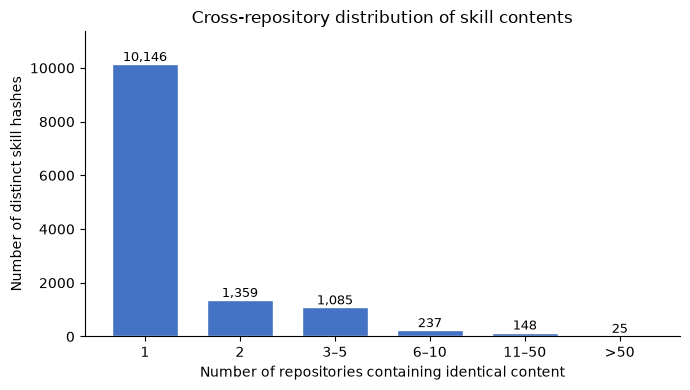

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
counts = reuse_categories_df["unique_hashes"].to_numpy()
bars = ax.bar(category_labels, counts, color="#4472C4", edgecolor="white", width=0.7)
ax.set_xlabel("Number of repositories containing identical content")
ax.set_ylabel("Number of distinct skill hashes")
ax.set_title("Cross-repository distribution of skill contents")
for bar, count in zip(bars, counts):
    ax.annotate(f"{count:,}", (bar.get_x() + bar.get_width()/2, bar.get_height()),
                ha="center", va="bottom", fontsize=9)
ax.set_ylim(0, counts.max() * 1.12)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
for extension, kwargs in [("pdf", {}), ("png", {"dpi": 300})]:
    output = FIGURES_DIR / f"rq2_cross_repository_reuse.{extension}"
    fig.savefig(output, bbox_inches="tight", **kwargs)
    print("Saved:", output)
plt.show()

## 8. Consistency checks

The assertions compare the calculated counts with those reported for the July 2026 GitSkills sample in the manuscript. They are intended to detect changes in the input data or analysis during reproduction. They should not be treated as expected values for other dataset releases.

In [8]:
expected = {
    "distinct_hashes": 13000,
    "shared_hashes": 2854,
    "total_artifacts": 29786,
    "shared_artifacts": 18855,
    "repo_unique_artifacts": 10931,
    "distribution_hashes": [10146, 1359, 1085, 237, 148, 25],
    "distribution_occurrences": [10931, 3376, 5755, 2639, 4589, 2496],
    "maximum_repositories": 132,
    "maximum_occurrences": 188,
}
actual = {
    "distinct_hashes": unique_hashes,
    "shared_hashes": shared_hashes,
    "total_artifacts": total_artifacts,
    "shared_artifacts": shared_artifacts,
    "repo_unique_artifacts": repo_unique_artifacts,
    "distribution_hashes": reuse_categories_df["unique_hashes"].astype(int).tolist(),
    "distribution_occurrences": reuse_categories_df["artifact_occurrences"].astype(int).tolist(),
    "maximum_repositories": int(hash_groups_df["repository_count"].max()),
    "maximum_occurrences": int(hash_groups_df["occurrences"].max()),
}
for key, expected_value in expected.items():
    assert actual[key] == expected_value, f"{key}: got {actual[key]}, expected {expected_value}"
assert round(shared_hash_pct, 2) == 21.95
assert round(shared_artifact_pct, 2) == 63.30
print("All RQ2 baseline checks passed.")

All RQ2 baseline checks passed.


## 9. Findings and limitations

Of the 13,000 distinct contents, 2,854 (21.95%) occur in more than one repository. These contents account for 18,855 of the 29,786 artifact occurrences (63.30%). Thus, a relatively small proportion of distinct contents contributes a majority of the recorded occurrences.

This is evidence of identical instruction-file contents across repositories, not necessarily copying between their maintainers. Repository mirrors, collections of skills, templates, or common upstream sources could produce the same pattern. In addition, the GitSkills sample was selected by content hash rather than by randomly selecting repositories, so the percentages should not be generalized to all GitHub repositories.

The hash comparison covers the contents of `SKILL.md` files, not their surrounding folders. Repositories with matching instruction files may contain different supporting scripts or reference materials. The analysis also does not measure semantic similarity, provenance, or changes over time.

The next notebook examines whether the overlap estimates change when large repositories are excluded or when the analysis is restricted by available metadata and filename.

In [9]:
conn.close()
print("Read-only database connection closed.")

Read-only database connection closed.
